# Native MoE: continued pre-training (CPT)

English | [简体中文](02_moe_finetune.zh-CN.ipynb)

## Goal

Train a real, randomly initialized tiny OLMoE, inspect router/expert gradients, resume an epoch checkpoint and reload native artifacts. Then adapt attention **and native 3D expert parameters** with LoRA. These synthetic examples validate mechanics, not model quality or large-model GPU fit. MoE is an architecture within Base/Instruct, not another task.

## Setup

Use a Python kernel with `.[llm-base,notebooks,publish]`. Only Colab installs below. SDK pins: Transformers 5.18.0, PEFT 0.18.1, Accelerate 1.15.0. Default runs are CPU/fp32 and download no model weights. No uploads occur. Keep real datasets, credentials and checkpoints outside Git.

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
if IN_COLAB:
    ROOT = Path("/content/advai-notebooks")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/advai-x/advai-notebooks.git", str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e",
                    f"{ROOT}[llm-base,notebooks,publish]"], check=True)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "pyproject.toml").is_file())
print("Repository ready; no model download requested.")

Repository ready; no model download requested.


In [2]:
import uuid
import torch
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from transformers import TrainerCallback
from transformers.utils import logging as hf_logging
from advai_notebooks.common.runtime import setup
from advai_notebooks.llm.base.config import load_config
from advai_notebooks.llm.base.data import load_data, prepare_data
from advai_notebooks.llm.base.model import BaseModel
from advai_notebooks.llm.base.pipeline import run
from advai_notebooks.llm.base.publish import publish
from advai_notebooks.llm.moe import describe

hf_logging.disable_progress_bar()
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})
run_id = uuid.uuid4().hex[:8]
cfg = load_config(ROOT / "configs/llm/base/moe/smoke.yaml", ROOT)
cfg.output_dir = f"outputs/llm/base/moe-tutorial-{run_id}"
print({"model": cfg.model.id, "architecture": cfg.model.architecture,
       "seed": cfg.training.seed, "dtype": cfg.model.dtype})

{'model': 'tiny-olmoe', 'architecture': 'moe', 'seed': 42, 'dtype': 'float32'}


## Steps

### 1. Validate data and inventory actual parameters

The task owns document/conversation splitting and supervision. The tiny native MoE has four experts per layer and selects two per token. Active experts do **not** reduce resident weights.

In [3]:
rows, summary = load_data(cfg)
initial = BaseModel(cfg.model, setup(cfg), cfg.root, cfg.training, cfg.generation)
prepared = prepare_data(rows, initial, cfg)
print({"splits": summary["splits"],
       "encoded_rows": {k: len(v) for k, v in prepared.items()}})
print(describe(initial.model))
del initial, prepared

{'splits': {'train': 8, 'validation': 2, 'test': 2}, 'encoded_rows': {'train': 8, 'validation': 2, 'test': 2}}
{'model_type': 'olmoe', 'num_experts': 4, 'experts_per_token': 2, 'total_parameters': 25712, 'trainable_parameters': 25712, 'weight_bytes': 102848, 'router_trainable': True, 'aux_loss_coef': 0.01, 'parameter_dtypes': ['torch.float32'], 'note': 'Actual parameter storage, not peak training memory or active-parameter size.'}


### 2. Train full weights, interrupt after a complete epoch, then resume

`latest` resolves to a native Trainer checkpoint with optimizer/scheduler/RNG state. Full MoE restoration uses native weight-layout conversion before Trainer restores the remaining state. Inference exports cannot resume. Keep config/data/runtime unchanged.

In [4]:
class StopAfterEpochOne(TrainerCallback):
    def on_save(self, args, state, control, **kwargs):
        if state.epoch >= 1:
            control.should_training_stop = True

first = run(cfg, callbacks=[StopAfterEpochOne()])
assert not first["training"]["completed"]
report = run(cfg, resume=cfg.path(cfg.output_dir) / "latest")
assert report["training"]["completed"]
audit = report["training"]["moe_gradients"]
assert audit["groups"]["router"]["nonzero_gradient_steps"] > 0
assert audit["groups"]["experts"]["nonzero_gradient_steps"] > 0
print({"selected_epoch": report["training"]["best_epoch"], "gradient_audit": audit})

{'selected_epoch': 2, 'gradient_audit': {'optimizer_steps': 4, 'groups': {'router': {'nonzero_gradient_steps': 4, 'trainable_tensors': 1, 'last_nonzero_tensors': 1, 'last_post_clip_grad_norm': 0.006714767969998869}, 'experts': {'nonzero_gradient_steps': 4, 'trainable_tensors': 2, 'last_nonzero_tensors': 2, 'last_post_clip_grad_norm': 0.02425513094613731}, 'other': {'nonzero_gradient_steps': 4, 'trainable_tensors': 10, 'last_nonzero_tensors': 10, 'last_post_clip_grad_norm': 0.9996826908263979}}}}


### 3. Compare language loss separately from routing diagnostics

Validation NLL selects the checkpoint, including epoch zero; test is report-only. NLL uses shifted supervision tokens, PPL = exp(NLL). The native auxiliary loss is **not** added to NLL/PPL. During accumulation the objective is a target-token-weighted mean of microbatch-local routing losses, not the nonlinear router loss of one concatenated batch.

In [5]:
table = "| Test diagnostic | Baseline | Selected |\n| --- | ---: | ---: |\n"
for name in ("nll", "perplexity"):
    a, b = [report[key]["metrics"][name]
            for key in ("baseline_test", "finetuned_test")]
    table += f"| {name} | {a:.4f} | {b:.4f} |\n"
a, b = [report[key]["moe"]["aux_loss"]
        for key in ("baseline_test", "finetuned_test")]
table += f"| Router auxiliary loss (not NLL) | {a:.4f} | {b:.4f} |\n"
display(Markdown(table))
print("Synthetic smoke only — this is not a quality benchmark.")

| Test diagnostic | Baseline | Selected |
| --- | ---: | ---: |
| nll | 4.8702 | 4.7234 |
| perplexity | 130.3449 | 112.5510 |
| Router auxiliary loss (not NLL) | 2.0027 | 1.9994 |


Synthetic smoke only — this is not a quality benchmark.


### 4. Inspect expert utilization

The chart uses the selected model's test report, all nonpadding input tokens (including SFT prompts), and native MoE-layer order. Shares divide **top-k assignments**, sum to 100%, and start from zero. The dotted line is equal allocation, not a quality target. Small synthetic counts have no benchmark meaning.

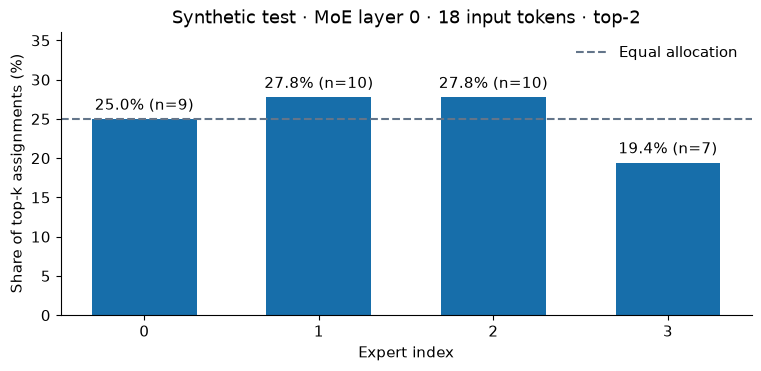

In [6]:
layer = report["finetuned_test"]["moe"]["layers"][0]
counts, shares = layer["assignment_counts"], layer["assignment_share"]
assert sum(counts) == layer["input_tokens"] * 2
assert abs(sum(shares) - 1) < 1e-8
fig, ax = plt.subplots(figsize=(7.5, 3.6), layout="constrained")
bars = ax.bar(range(len(shares)), [100 * s for s in shares], color="#176EAA", width=0.6)
ax.axhline(100 / len(shares), color="#63758A", linestyle="--", label="Equal allocation")
ax.bar_label(bars, labels=[f"{100*s:.1f}% (n={n})" for s, n in zip(shares, counts)],
             padding=4, bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
ax.set(ylim=(0, max(100 / len(shares), max(shares) * 100) * 1.3),
       xticks=range(len(shares)), xlabel="Expert index",
       ylabel="Share of top-k assignments (%)",
       title=f"Synthetic test · MoE layer 0 · {layer['input_tokens']} input tokens · top-2")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
fig.savefig(cfg.path(cfg.output_dir) / "expert-utilization.png", dpi=140)
plt.show()

### 5. Adapt attention and 3D expert parameters with LoRA

MoE LoRA freezes the router in v1. `target_modules` covers attention; `target_parameters` covers native expert tensors. PEFT 0.18.1 emits a generic unsupported-layer warning for these parameter wrappers; the checks below establish gradients and merge/reload parity only for this tested tiny backend. Revalidate on real checkpoints before a long run.

In [7]:
adapter_cfg = load_config(ROOT / "configs/llm/base/moe/smoke_experts_lora.yaml", ROOT)
adapter_cfg.output_dir = f"outputs/llm/base/moe-experts-tutorial-{run_id}"
adapter_report = run(adapter_cfg)
adapter_audit = adapter_report["training"]["moe_gradients"]["groups"]
assert adapter_audit["router"]["trainable_tensors"] == 0
assert adapter_audit["experts"]["nonzero_gradient_steps"] > 0
assert adapter_audit["other"]["nonzero_gradient_steps"] > 0
print(adapter_audit)

/Users/xuyi/Documents/workspace/advai-notebooks/.venv-regression/lib/python3.12/site-packages/peft/tuners/tuners_utils.py:212: UserWarning: Unsupported layer type '<class 'transformers.models.olmoe.modeling_olmoe.OlmoeExperts'>' encountered, proceed at your own risk.
  warnings.warn(f"Unsupported layer type '{type(module)}' encountered, proceed at your own risk.", UserWarning)


{'router': {'nonzero_gradient_steps': 0, 'trainable_tensors': 0, 'last_nonzero_tensors': 0, 'last_post_clip_grad_norm': 0.0}, 'experts': {'nonzero_gradient_steps': 4, 'trainable_tensors': 4, 'last_nonzero_tensors': 4, 'last_post_clip_grad_norm': 0.012023557255514458}, 'other': {'nonzero_gradient_steps': 4, 'trainable_tensors': 4, 'last_nonzero_tensors': 4, 'last_post_clip_grad_norm': 0.17718296517098983}}


/Users/xuyi/Documents/workspace/advai-notebooks/.venv-regression/lib/python3.12/site-packages/peft/tuners/tuners_utils.py:212: UserWarning: Unsupported layer type '<class 'transformers.models.olmoe.modeling_olmoe.OlmoeExperts'>' encountered, proceed at your own risk.
  warnings.warn(f"Unsupported layer type '{type(module)}' encountered, proceed at your own risk.", UserWarning)


## Checks

Reload the adapter, merge a copy, compare logits and greedy generation, and preview publication offline. This verifies artifact contracts, not response quality. Only trained adapters change; original base weights remain frozen.

In [8]:
adapter = BaseModel.load(adapter_report["export"])
merged_path = adapter.save(adapter_cfg.path(adapter_cfg.output_dir) / "merged", merged=True)
merged = BaseModel.load(merged_path)
batch = adapter.tokenizer("the sky is blue", return_tensors="pt")
adapter.model.eval()
merged.model.eval()
with torch.no_grad():
    torch.testing.assert_close(adapter.model(**batch).logits,
                               merged.model(**batch).logits, rtol=1e-5, atol=1e-5)
plan = publish(adapter_report["export"], "example/moe-base-smoke", dry_run=True)
names = {item["path"] for item in plan["files"]}
assert "adapter_model.safetensors" in names
assert not names & {"optimizer.pt", "rng_state.pth", "raw-data.jsonl", ".env"}
print({"native_merge_equal": True, "publication": plan["status"], "files": len(names)})

{'native_merge_equal': True, 'publication': 'dry_run', 'files': 11}


In [9]:
result = adapter.generate(["the sky is"], max_new_tokens=3)
assert result == merged.generate(["the sky is"], max_new_tokens=3)
print({"synthetic_continuation": result})

{'synthetic_continuation': ['is is is']}


## Next Steps

Read the [MoE guide](../../../docs/llm-moe.md). Try `smoke_qwen3.yaml` for the second native backend or `smoke_lora.yaml` for attention-only adapters. Copy `olmoe_lora.yaml` or `qwen3_lora.yaml` into ignored `configs/local/`; replace data/output paths and audit the pinned model/tokenizer/license. The Qwen Instruct preset deliberately uses an explicit text-only non-thinking template. Real weights need all experts resident (roughly 14 GB OLMoE / 61 GB Qwen3 in bf16 before training overhead). Weight budgets are lower-bound guards, not fit promises. Real GPU training, AMP recovery and domain quality are unverified here; no QLoRA, expert parallelism or MoE PPO/GRPO is provided. Use persistent storage for Colab checkpoints; free Colab fit is not guaranteed.